In [1]:
!pip install rank_bm25
!pip install -q git+https://github.com/huggingface/transformers.git
!pip install -q accelerate bitsandbytes peft datasets trl qwen-vl-utils

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 521.0/521.0 kB 19.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.1.1 requires transformers<5.0.0,>=4.41.0, but you have transformers 5.0.0.dev0 which is incompatible.
gradio 5.49.1 requires pydantic<2.12,>=2.0, but you have pydantic 2.12.5 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 51.0 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
from rank_bm25 import BM25Okapi
import string
import re
import os
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoProcessor, Qwen2VLForConditionalGeneration, BitsAndBytesConfig
from PIL import Image
from peft import PeftModel
from qwen_vl_utils import process_vision_info
import json
from tqdm import tqdm
import random
import matplotlib.pyplot as plt
import cv2
import textwrap
from sklearn.metrics import ndcg_score
from scipy.stats import spearmanr
import seaborn as sns
import glob

In [3]:
class ClassicalRetriever:
    def __init__(self, data_path):
        print("--- Initializing Stage 1: Classical Retriever ---")
        
        # 1. Load Data
        self.df = pd.read_csv(data_path)
        print(f"Loaded {len(self.df)} items.")
        
        # 2. Prepare Text for Indexing
        print("Building Text Index...")
        self.df['search_text'] = (
            self.df['product_type'].fillna('') + " " + 
            self.df['item_name'].fillna('') + " " + 
            self.df['item_keywords'].fillna('')
        ).apply(self._preprocess)
        
        # 3. Build BM25 Index
        # Tokenize: Split by space
        tokenized_corpus = [doc.split(" ") for doc in self.df['search_text']]
        self.bm25 = BM25Okapi(tokenized_corpus)
        print("Retrieval Engine Ready.")

    def _preprocess(self, text):
        """
        Basic cleaning: Lowercase, remove punctuation, remove extra spaces.
        """
        text = str(text).lower()
        # Remove punctuation
        text = text.translate(str.maketrans('', '', string.punctuation))
        # Remove double spaces
        text = re.sub(r'\s+', ' ', text).strip()
        return text

    def search(self, query, category_filter=None, top_k=100):
        """
        Args:
            query (str): User text (e.g. "Modern Walnut Coffee Table")
            category_filter (str): OPTIONAL hard filter (e.g. "TABLE")
            top_k (int): Number of candidates to return
        Returns:
            DataFrame of top matches
        """
        # 1. Get BM25 Scores for EVERY item in database
        clean_query = self._preprocess(query).split(" ")
        scores = self.bm25.get_scores(clean_query)
        
        # Add scores to a temporary view of the dataframe
        self.df['bm25_score'] = scores
        
        # 2. Apply "The Hard Filter" (SQL-Style)
        if category_filter:
            # Check if product_type contains the filter string (Case Insensitive)
            mask = self.df['product_type'].str.contains(category_filter, case=False, na=False)
            results = self.df[mask].copy()
            
            # Fallback: If filter is too strict and returns 0, ignore it
            if len(results) == 0:
                print(f"Warning: Filter '{category_filter}' returned 0 results. Returning global search.")
                results = self.df.copy()
        else:
            results = self.df.copy()

        # 3. Sort by Score and Return Top K
        results = results.sort_values('bm25_score', ascending=False).head(top_k)
        
        # Return only relevant columns
        return results[['product_type', 'item_name', 'full_path', 'bm25_score']]

DATA_PATH = "/kaggle/input/style-search-siglip-generated-pairs/clean_furniture_data.csv" 
retriever = ClassicalRetriever(DATA_PATH)

--- Initializing Stage 1: Classical Retriever ---
Loaded 500 items.
Building Text Index...
Retrieval Engine Ready.


In [4]:
# Case 1: The "Vague" Search
# This simulates a user just typing keywords. You might get Lamps mixed with Tables.
print("--- Search: 'Modern Glass' (No Filter) ---")
results_vague = retriever.search("Modern Glass", top_k=5)
print(results_vague[['item_name', 'bm25_score']].to_string())

print("\n--- Search: 'Modern Glass Lamp' (No Filter) ---")
results_vague = retriever.search("Modern Glass Lamp", top_k=5)
print(results_vague[['item_name', 'bm25_score']].to_string())

# Case 2: The "Filtered" Search (Solving the Semantic Gap)
# We strictly ask for 'LAMP'. Even if a table is made of 'Modern Glass', it should NOT appear.
print("\n--- Search: 'Modern Glass' (Filter: LAMP) ---")
results_filtered = retriever.search("Modern Glass", category_filter="LAMP", top_k=5)
print(results_filtered[['item_name', 'bm25_score']].to_string())

# Case 3: The "Complex" Search
# Testing if it picks up keywords like 'Farmhouse'
print("\n--- Search: 'Rustic Farmhouse' (Filter: CHAIR) ---")
results_chair = retriever.search("Rustic Farmhouse", category_filter="CHAIR", top_k=5)
print(results_chair[['item_name', 'bm25_score']].to_string())

--- Search: 'Modern Glass' (No Filter) ---
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   item_name  bm25_score
57                                                                                                                                                                                  

In [5]:
class VectorRetriever:
    def __init__(self, db_path, model_id="google/siglip-so400m-patch14-384"):
        print("--- Initializing Stage 2: Vector (Vibe) Retriever ---")
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        
        # 1. Load the Database (The .pt file we just made)
        print(f"Loading Vector DB from {db_path}...")
        checkpoint = torch.load(db_path, map_location="cpu", weights_only=False) # Load to CPU first
        
        self.metadata = checkpoint['metadata']
        self.visual_vectors = checkpoint['visual_vectors'].to(self.device)
        self.text_vectors = checkpoint['text_vectors'].to(self.device)
        
        print(f"DB Loaded: {self.visual_vectors.shape[0]} items.")

        # 2. Load SigLIP Model (For encoding the USER'S query image)
        print(f"Loading SigLIP Model ({model_id})...")
        self.model = AutoModel.from_pretrained(model_id).to(self.device).eval()
        self.processor = AutoProcessor.from_pretrained(model_id)
        print("Vector Engine Ready.")

    def embed_image(self, image_path):
        """
        Embeds a single query image on the fly.
        """
        image = Image.open(image_path).convert("RGB")
        
        # Preprocess
        inputs = self.processor(images=image, return_tensors="pt").to(self.device)
        
        with torch.no_grad():
            # Get Vision Features
            embedding = self.model.get_image_features(**inputs)
            # Normalize! (Critical for cosine similarity)
            embedding = F.normalize(embedding, p=2, dim=-1)
            
        return embedding

    def search_by_vibe(self, room_image_path, candidate_indices=None, top_k=50):
        """
        Args:
            room_image_path (str): Path to user's uploaded photo.
            candidate_indices (list): OPTIONAL list of row IDs from Stage 1 (Classical Search).
                                      If None, searches the whole DB.
            top_k (int): Number of results to return.
        """
        # 1. Embed the User's Room
        query_emb = self.embed_image(room_image_path) # Shape: (1, 768)
        
        # 2. Define the Search Space
        if candidate_indices is not None and len(candidate_indices) > 0:
            valid_indices = torch.tensor(candidate_indices, device=self.device)
            target_vectors = self.visual_vectors.index_select(0, valid_indices)
        else:
            target_vectors = self.visual_vectors
            valid_indices = torch.arange(len(self.metadata), device=self.device)

        # 3. Calculate Cosine Similarity (Vector Math)
        # Query (1, 768) @ Targets (N, 768).T -> Scores (1, N)
        scores = torch.matmul(query_emb, target_vectors.T).squeeze(0)
        
        # 4. Get Top K
        k_actual = min(top_k, len(scores))
        top_results = torch.topk(scores, k=k_actual)
        
        # 5. Map back to Global Indices
        local_indices = top_results.indices
        global_indices = valid_indices[local_indices].cpu().numpy()
        similarity_scores = top_results.values.cpu().numpy()
        
        # 6. Retrieve Metadata
        results_df = self.metadata.iloc[global_indices].copy()
        results_df['visual_score'] = similarity_scores
        
        return results_df[['product_type', 'item_name', 'full_path', 'visual_score']]

vector_retriever = VectorRetriever("/kaggle/input/style-search-siglip-generated-pairs/furniture_style_db.pt")

--- Initializing Stage 2: Vector (Vibe) Retriever ---
Loading Vector DB from /kaggle/input/style-search-siglip-generated-pairs/furniture_style_db.pt...
DB Loaded: 500 items.
Loading SigLIP Model (google/siglip-so400m-patch14-384)...


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.51G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Vector Engine Ready.


User Query Image: /kaggle/input/house-rooms/room-dataset/dining/dining_648.jpg
User Text Query: 'Wooden Table'

Stage 1 found 47 text-relevant candidates.

--- STAGE 2 RESULTS (Top 5 Visual Matches) ---
       product_type  visual_score                                                                                                                                                                                                                                         item_name
266           CHAIR      0.570013                                                                                                                                                                                        Movian Elbe – Sedia da pranzo con bottoni, colore blu lago
429           CHAIR      0.557793  Amazon Brand - Movian Galga - Silla relax, 90 x 105 x 98 cm (largo x ancho x alto), piel sintética marrón oscuro, Amazon Brand - Movian Galga - cadeira relax, 90 x 105 x 98 cm (comprimento x largura x altura), 

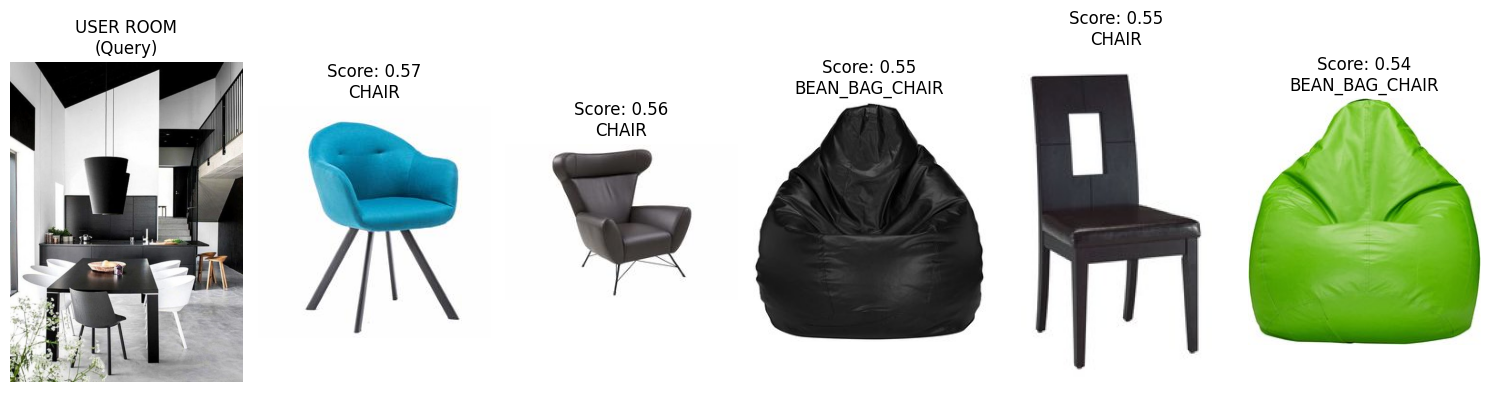

In [6]:
# ==========================================
# DEMO: STAGE 1 + STAGE 2
# ==========================================
df_rooms = pd.read_csv("/kaggle/input/style-search-siglip-generated-pairs/clean_room_data.csv")

# 1. Pick a "User Room" (Randomly from your dataset)
user_room_path = df_rooms['path'].sample(1).iloc[0]
print(f"User Query Image: {user_room_path}")
print(f"User Text Query: 'Wooden Table'")

# 2. STAGE 1: Classical Retrieval (The Filter)
stage1_results = retriever.search("Modern Chair", category_filter="CHAIR", top_k=200)
print(f"\nStage 1 found {len(stage1_results)} text-relevant candidates.")

# Extract the INDICES (Row Numbers) of these candidates
candidate_ids = stage1_results.index.tolist()

# 3. STAGE 2: Vector Re-Ranking (The Vibe Check)
stage2_results = vector_retriever.search_by_vibe(
    user_room_path, 
    candidate_indices=candidate_ids, 
    top_k=5
)

print("\n--- STAGE 2 RESULTS (Top 5 Visual Matches) ---")
print(stage2_results[['product_type', 'visual_score', 'item_name']].to_string())

# 4. Visualize

def show_results(room_path, results_df):
    plt.figure(figsize=(15, 5))
    
    # Plot Query Room
    ax = plt.subplot(1, len(results_df)+1, 1)
    img = cv2.imread(room_path)
    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("USER ROOM\n(Query)")
    plt.axis("off")
    
    # Plot Results
    for i, (_, row) in enumerate(results_df.iterrows()):
        ax = plt.subplot(1, len(results_df)+1, i+2)
        img = cv2.imread(row['full_path'])
        if img is not None:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Score: {row['visual_score']:.2f}\n{row['product_type']}")
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

show_results(user_room_path, stage2_results)

In [7]:
class StyleAgent:
    def __init__(self, base_model_id, adapter_path, batch_size=4):
        print("--- Initializing Stage 3: The Style Agent ---")
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.batch_size = batch_size
        # 1. Load 4-Bit Config (Same as Training)
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
        )

        # 2. Load Base Model
        print(f"Loading Base Model ({base_model_id})...")
        base_model = Qwen2VLForConditionalGeneration.from_pretrained(
            base_model_id,
            quantization_config=bnb_config,
            device_map="auto",
            attn_implementation="eager" # Use "sdpa" if on T4, "eager" on P100
        )

        # 3. Load LoRA Adapter
        print(f"Loading Fine-Tuned Brain from {adapter_path}...")
        self.model = PeftModel.from_pretrained(base_model, adapter_path)
        self.model.eval()
        
        self.processor = AutoProcessor.from_pretrained(base_model_id, min_pixels=256*256, max_pixels=512*512)

        self.processor.tokenizer.padding_side = "left"
        if self.processor.tokenizer.pad_token is None:
            self.processor.tokenizer.pad_token = self.processor.tokenizer.eos_token

        print("Agent Ready.")

    def re_rank(self, user_room_path, candidate_df, room_type = "room"):
        """
        Batched Re-Ranking.
        Args:
            batch_size (int): Try 4 for P100/T4. Try 8 if it fits.
        """
        results = []
        
        rows = candidate_df.to_dict('records')
        
        print(f"Agent analyzing {len(rows)} candidates (Batch Size: {self.batch_size})...")
        
        for i in tqdm(range(0, len(rows), self.batch_size), desc="Agent Batches"):
            batch_rows = rows[i : i + self.batch_size]
            
            # 1. Build Batch Messages
            batch_msgs = []
            for row in batch_rows:
                prompt = f"Analyze the stylistic compatibility of the {row['product_type']} for the {room_type}."
                msg = {
                    "role": "user",
                    "content": [
                        {"type": "image", "image": user_room_path},
                        {"type": "image", "image": row['full_path']},
                        {"type": "text", "text": prompt},
                    ],
                }
                batch_msgs.append(msg)
            
            # 2. Preprocess Batch
            text_prompts = [self.processor.apply_chat_template([m], tokenize=False, add_generation_prompt=True) for m in batch_msgs]
            image_inputs, video_inputs = process_vision_info(batch_msgs)
            
            inputs = self.processor(
                text=text_prompts,
                images=image_inputs,
                videos=video_inputs,
                padding=True, # CRITICAL for batching
                return_tensors="pt",
            )
            inputs = {k: v.to(self.model.device) for k, v in inputs.items()}

            # 3. Generate Batch
            with torch.no_grad():
                # Reduced max_new_tokens to 96 (we only need JSON)
                output_ids = self.model.generate(**inputs, max_new_tokens=96, do_sample=False)

            # 4. Decode Batch
            # Slice off input tokens
            generated_ids = [
                out_ids[len(in_ids):] for out_ids, in_ids in zip(output_ids, inputs["input_ids"])
            ]
            output_texts = self.processor.batch_decode(generated_ids, skip_special_tokens=True)
            
            # 5. Parse Batch Results
            for j, text_out in enumerate(output_texts):
                row_data = batch_rows[j]
                
                try:
                    clean = text_out.replace("```json", "").replace("```", "").strip()
                    # Soft regex parsing is safer than strict JSON load for small models
                    import re
                    s_match = re.search(r'"score":\s*([0-9.]+)', clean)
                    r_match = re.search(r'"rationale":\s*"(.*?)"', clean)
                    
                    score = float(s_match.group(1)) if s_match else 0.0
                    rationale = r_match.group(1) if r_match else clean[:100]
                    
                except:
                    score = 0.0
                    rationale = "Error parsing agent output."

                results.append({
                    "product_type": row_data['product_type'],
                    "item_name": row_data['item_name'],
                    "full_path": row_data['full_path'],
                    "stage2_score": row_data['visual_score'],
                    "agent_score": score,
                    "rationale": rationale
                })

        # Sort final results
        final_df = pd.DataFrame(results)
        return final_df.sort_values(by="agent_score", ascending=False)


# Initialize Stage 3
agent = StyleAgent("Qwen/Qwen2-VL-2B-Instruct", "/kaggle/input/style-search-qwen2-5vl-generated-pairs/style_agent_qwen2b_final/style_agent_qwen2b_final", batch_size=8)

--- Initializing Stage 3: The Style Agent ---
Loading Base Model (Qwen/Qwen2-VL-2B-Instruct)...


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (5 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Agent Ready.



USER QUERY: 'I need a modern Chair'
--- Stage 1: Filtering for category 'CHAIR' ---
Found 47 text matches.
--- Stage 2: Visual Ranking against Room ---
--- Stage 3: Agent Critique (Top 20 items) ---
Agent analyzing 20 candidates (Batch Size: 8)...


Agent Batches: 100%|██████████| 3/3 [00:55<00:00, 18.36s/it]
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 48307 (\N{HANGUL SYLLABLE BES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 45912 (\N{HANGUL SYLLABLE DE

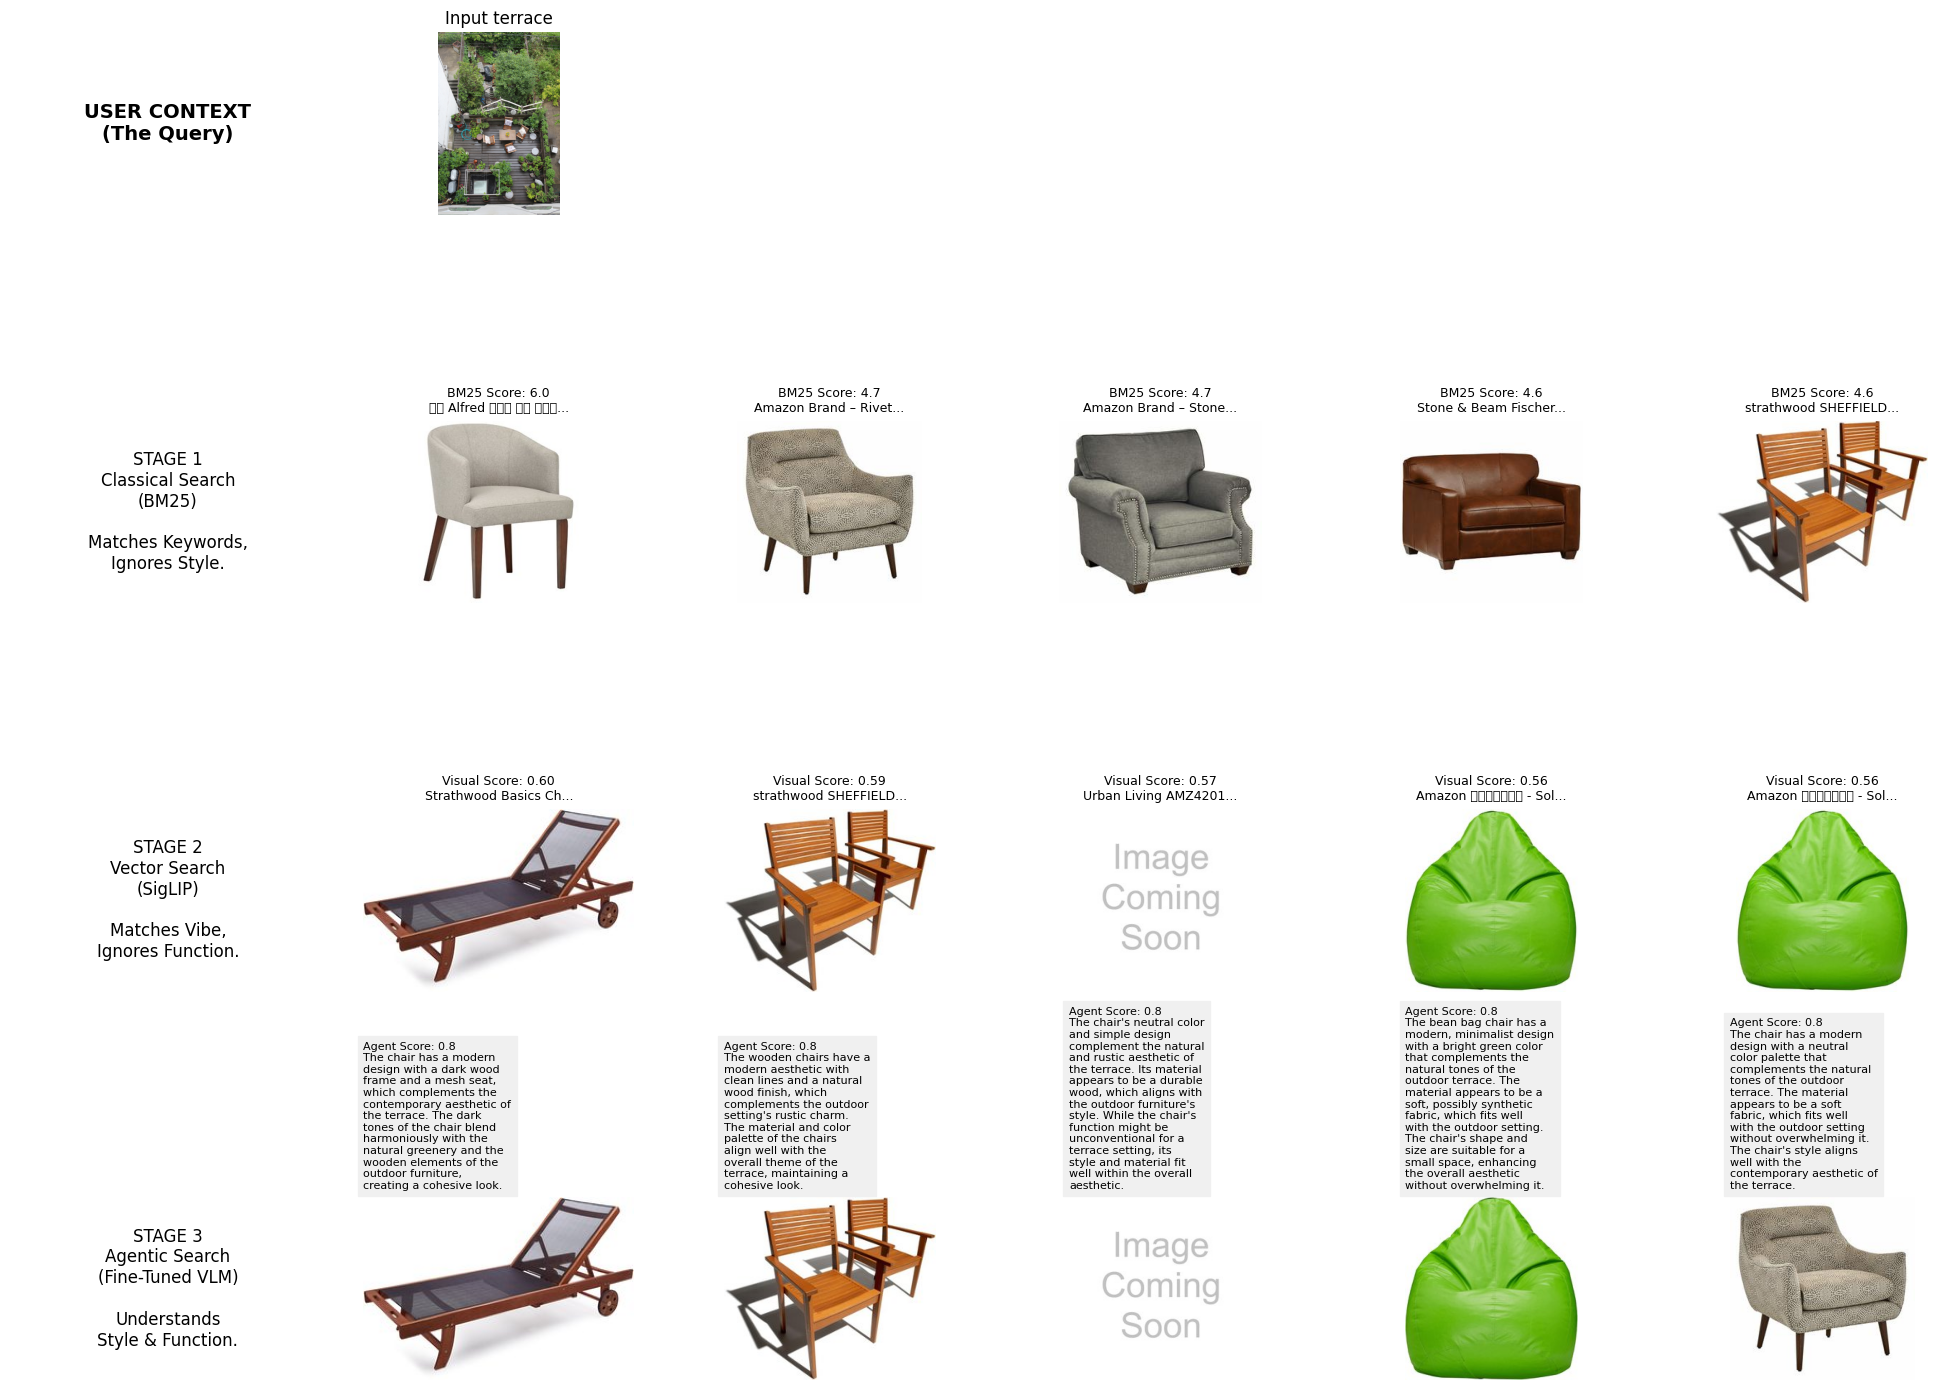


USER QUERY: 'I need a vintage Lamp'
--- Stage 1: Filtering for category 'LAMP' ---
Found 47 text matches.
--- Stage 2: Visual Ranking against Room ---
--- Stage 3: Agent Critique (Top 20 items) ---
Agent analyzing 20 candidates (Batch Size: 8)...


Agent Batches: 100%|██████████| 3/3 [00:52<00:00, 17.46s/it]
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 48307 (\N{HANGUL SYLLABLE BES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 45912 (\N{HANGUL SYLLABLE DEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 47700 (\N{HANGUL SYLLABLE ME}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_24/2660061733.py:106: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE P

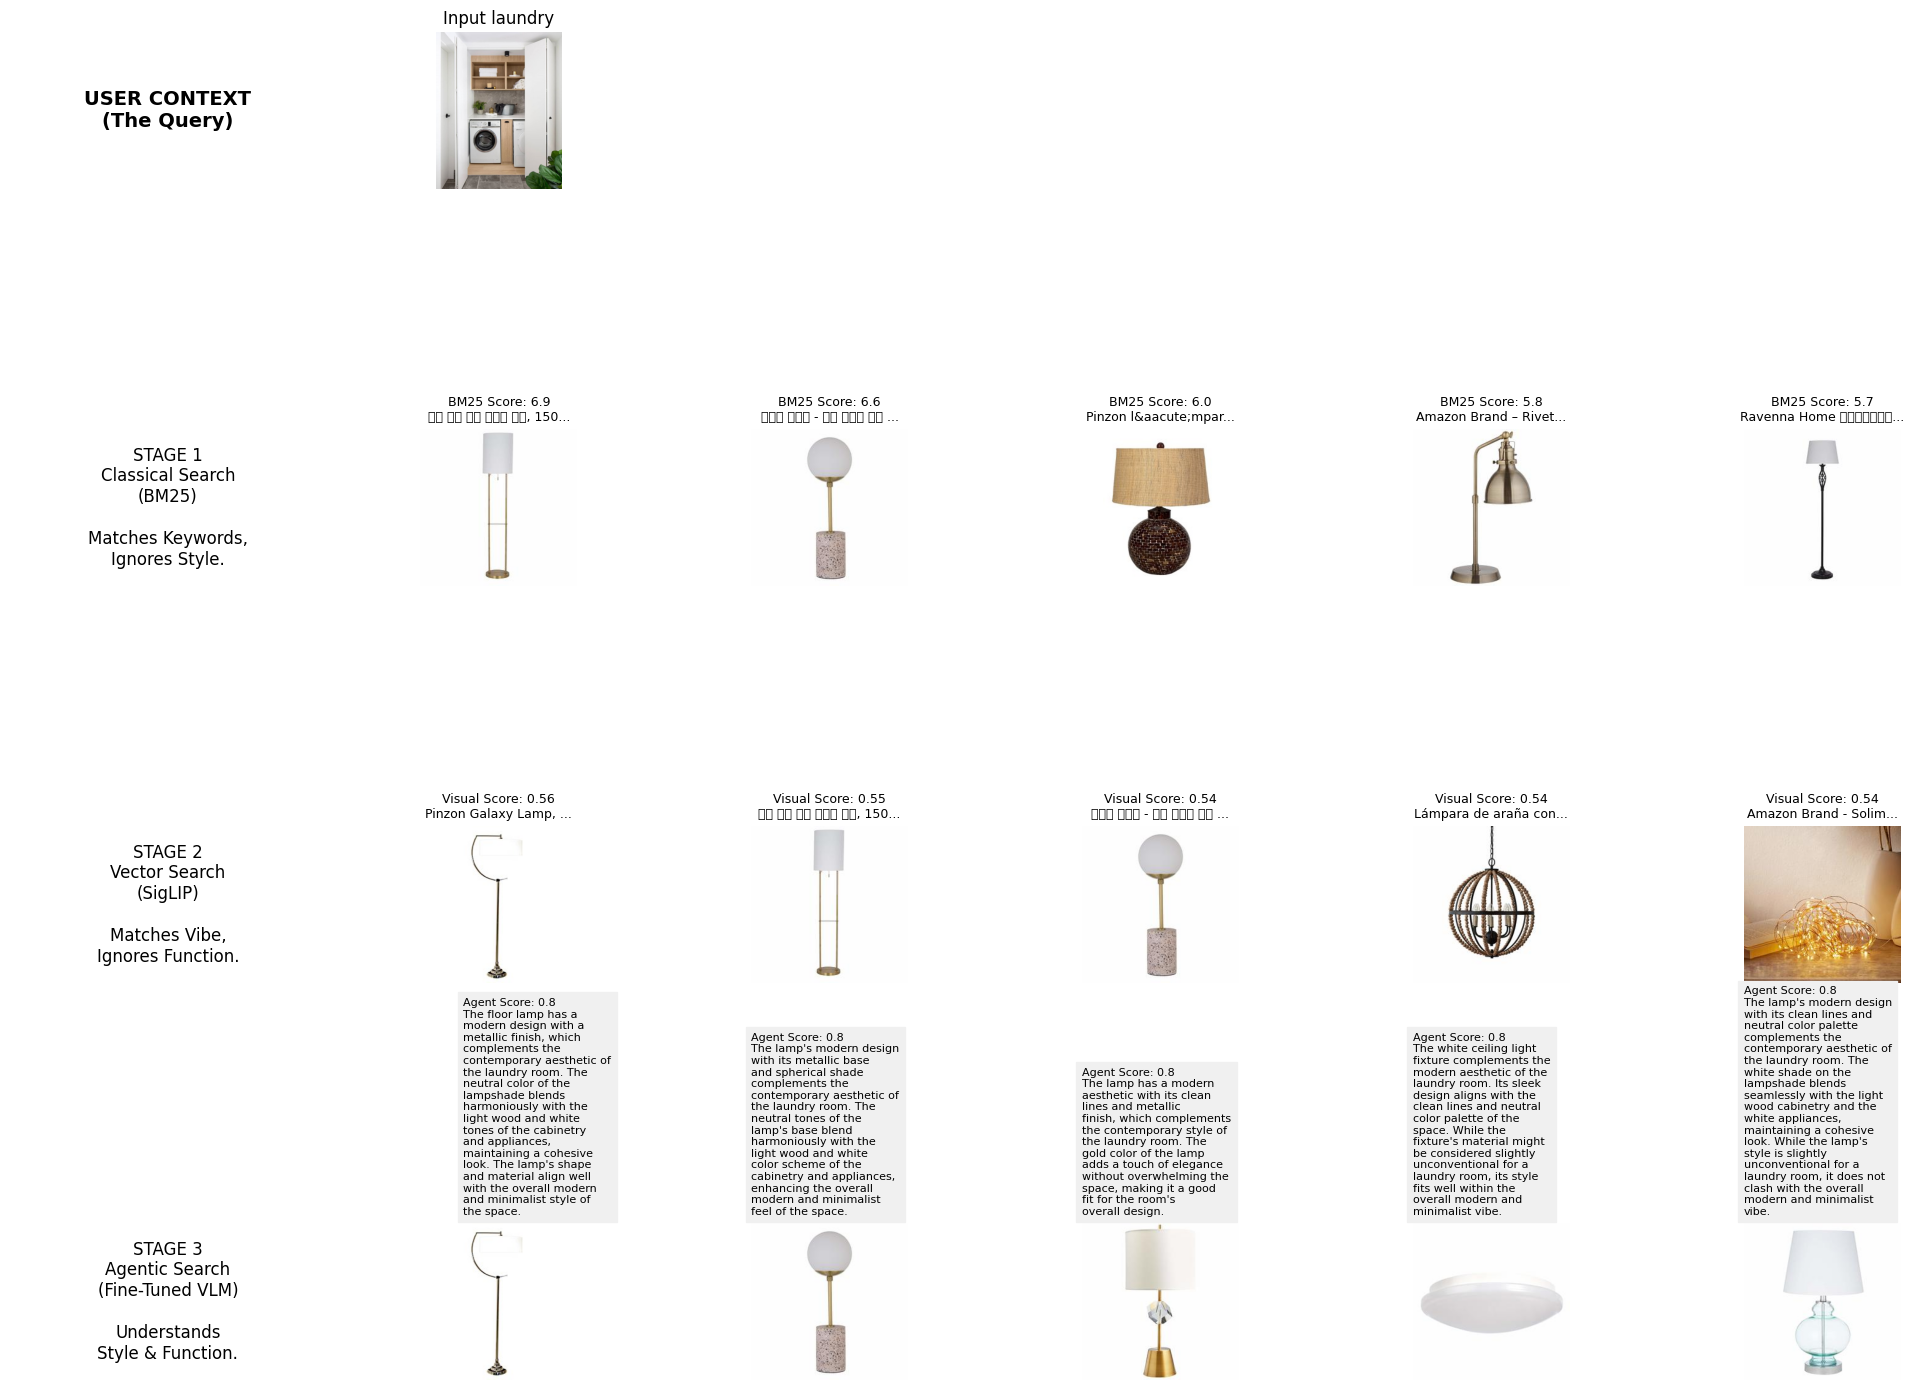

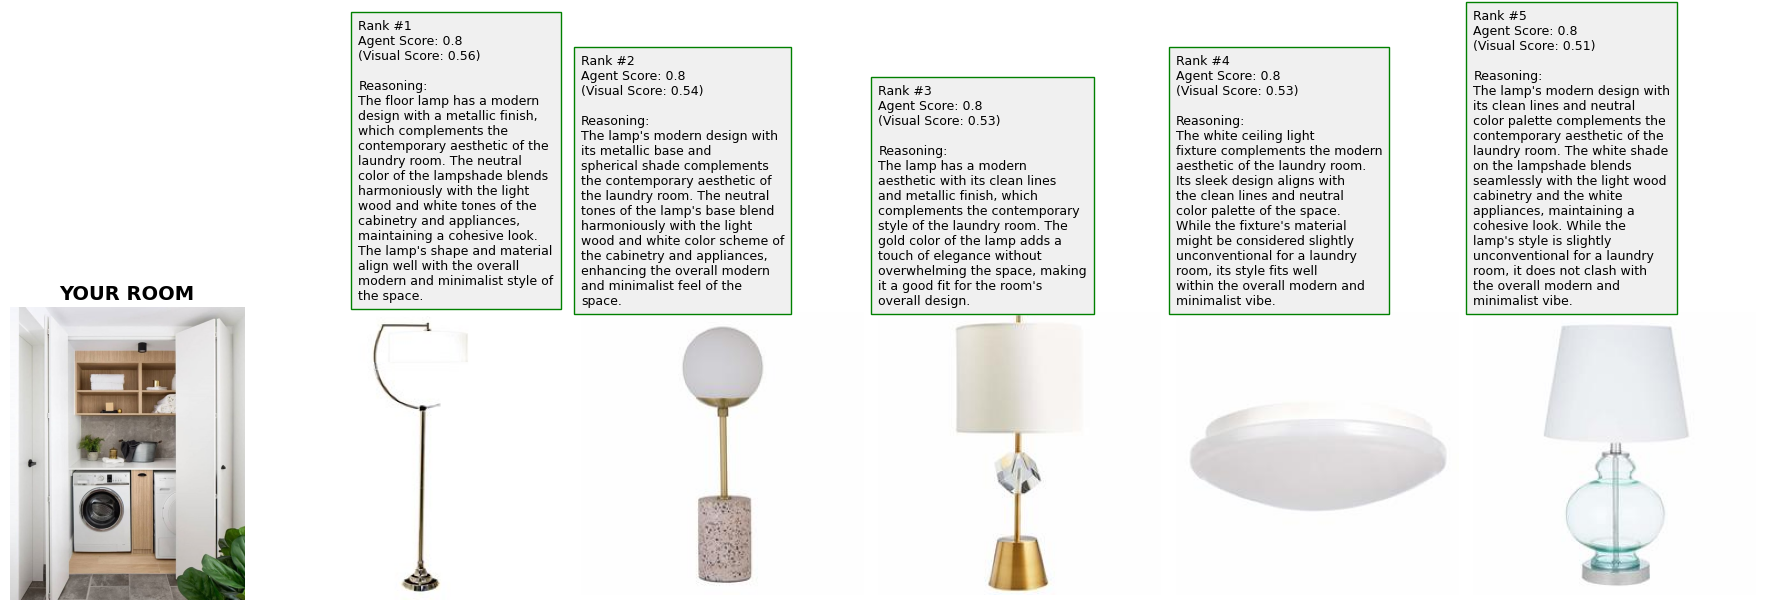

In [8]:
# ==========================================
# THE FULL PIPELINE
# ==========================================

def search_engine_pipeline(user_query, user_room_image, test_room_type, top_k_stage1=200, top_k_stage2=20, top_k_stage3=5):
    print(f"\nUSER QUERY: '{user_query}'")
    
    # --- STAGE 1: CLASSICAL FILTER ---
    # In a real app, will use an LLM router here to extract the last word as the "Category" (e.g. "Modern Chair" -> "CHAIR")
    category_guess = user_query.split()[-1].upper() 
    
    print(f"--- Stage 1: Filtering for category '{category_guess}' ---")
    stage1_res = retriever.search(user_query, category_filter=category_guess, top_k=top_k_stage1)
    print(f"Found {len(stage1_res)} text matches.")
    stage1_display = stage1_res.head(5).copy() # Top 5 text matches
    
    if len(stage1_res) == 0:
        return pd.DataFrame() # No results

    # --- STAGE 2: VISUAL VIBE CHECK ---
    print(f"--- Stage 2: Visual Ranking against Room ---")
    stage2_res = vector_retriever.search_by_vibe(
        user_room_image, 
        candidate_indices=stage1_res.index.tolist(), 
        top_k=top_k_stage2
    )
    stage2_display = stage2_res.head(5).copy()
    
    # --- STAGE 3: AGENTIC CRITIQUE ---
    print(f"--- Stage 3: Agent Critique (Top {top_k_stage2} items) ---")
    final_res = agent.re_rank(user_room_image, stage2_res, room_type=test_room_type)
    stage3_display = final_res.head(5).copy()

    visualize_funnel(user_room_image,test_room_type, stage1_display, stage2_display, stage3_display)
    
    return final_res.head(top_k_stage3)

def visualize_funnel(room_path, test_room_type, s1_df, s2_df, s3_df):
    """
    Plots a 4-row grid: User Room | Classical Results | Vector Results | Agent Results
    """
    rows = 4
    cols = 6 # 1 label + 5 images
    plt.figure(figsize=(20, 14))
    
    # --- ROW 1: USER CONTEXT ---
    ax = plt.subplot(rows, cols, 1)
    plt.text(0.5, 0.5, "USER CONTEXT\n(The Query)", ha='center', va='center', fontsize=14, fontweight='bold')
    plt.axis("off")
    
    ax = plt.subplot(rows, cols, 2)
    img = cv2.imread(room_path)
    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Input {test_room_type}")
    plt.axis("off")
    
    # --- ROW 2: CLASSICAL SEARCH ---
    ax = plt.subplot(rows, cols, cols+1)
    plt.text(0.5, 0.5, "STAGE 1\nClassical Search\n(BM25)\n\nMatches Keywords,\nIgnores Style.", ha='center', va='center', fontsize=12)
    plt.axis("off")
    
    for i, (_, row) in enumerate(s1_df.iterrows()):
        ax = plt.subplot(rows, cols, cols + i + 2)
        img = cv2.imread(row['full_path'])
        if img is not None:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"BM25 Score: {row['bm25_score']:.1f}\n{row['item_name'][:20]}...", fontsize=9)
        plt.axis("off")

    # --- ROW 3: VECTOR SEARCH ---
    ax = plt.subplot(rows, cols, 2*cols+1)
    plt.text(0.5, 0.5, "STAGE 2\nVector Search\n(SigLIP)\n\nMatches Vibe,\nIgnores Function.", ha='center', va='center', fontsize=12)
    plt.axis("off")
    
    for i, (_, row) in enumerate(s2_df.iterrows()):
        ax = plt.subplot(rows, cols, 2*cols + i + 2)
        img = cv2.imread(row['full_path'])
        if img is not None:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Visual Score: {row['visual_score']:.2f}\n{row['item_name'][:20]}...", fontsize=9)
        plt.axis("off")

    # --- ROW 4: AGENT SEARCH ---
    ax = plt.subplot(rows, cols, 3*cols+1)
    plt.text(0.5, 0.5, "STAGE 3\nAgentic Search\n(Fine-Tuned VLM)\n\nUnderstands\nStyle & Function.", ha='center', va='center', fontsize=12)
    plt.axis("off")
    
    for i, (_, row) in enumerate(s3_df.iterrows()):
        ax = plt.subplot(rows, cols, 3*cols + i + 2)
        img = cv2.imread(row['full_path'])
        if img is not None:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        
        # Color border based on score
        color = 'green' if row['agent_score'] > 0.7 else 'orange'
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(3)
            
        # Wrap rationale
        rat = "\n".join(textwrap.wrap(row['rationale'], width=25))
        plt.title(f"Agent Score: {row['agent_score']}\n{rat}", fontsize=8, loc='left', backgroundcolor='#f0f0f0')
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# ==========================================
# RUN THE DEMO
# ==========================================
# Pick a room from your dataset
test_room = df_rooms.sample(1).iloc[0]
test_room_path = test_room['path']
test_room_type = test_room['subtype']

# Run the Full Funnel
search_engine_pipeline("I need a modern Chair", test_room_path, test_room_type)


# ==========================================
# RUN DEMO
# ==========================================
# Pick a random room
test_room = df_rooms.sample(1).iloc[0]
test_room_path = test_room['path']
test_room_type = test_room['subtype']

final_results = search_engine_pipeline("I need a vintage Lamp", test_room_path, test_room_type)

# Display

def show_final_results(room_path, results_df):
    plt.figure(figsize=(18, 6))
    
    # Plot User Room
    ax = plt.subplot(1, len(results_df)+1, 1)
    img = cv2.imread(room_path)
    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("YOUR ROOM", fontsize=14, fontweight='bold')
    plt.axis("off")
    
    # Plot Top Recommendations
    for i, (_, row) in enumerate(results_df.iterrows()):
        ax = plt.subplot(1, len(results_df)+1, i+2)
        img = cv2.imread(row['full_path'])
        if img is not None:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            
        # Color code border based on Agent Score
        score = row['agent_score']
        color = 'green' if score >= 0.8 else 'orange' if score >= 0.5 else 'red'
        
        rationale = "\n".join(textwrap.wrap(row['rationale'], width=30))
        
        title = (f"Rank #{i+1}\n"
                 f"Agent Score: {score}\n"
                 f"(Visual Score: {row['stage2_score']:.2f})\n\n"
                 f"Reasoning:\n{rationale}")
        
        plt.title(title, fontsize=9, loc='left', bbox=dict(facecolor='#f0f0f0', edgecolor=color, pad=5))
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

if not final_results.empty:
    show_final_results(test_room_path, final_results)
else:
    print("No results found!")

In [9]:
from sklearn.metrics import ndcg_score
import numpy as np
import pandas as pd
import random
from tqdm import tqdm
import torch.nn.functional as F

def evaluate_pipeline_performance(labeled_data_path, sample_rooms=20):
    print(f"--- Starting Evaluation (Sample: {sample_rooms} Rooms) ---")
    
    # 1. Load the Labeled Data
    try:
        df_eval = pd.read_json(labeled_data_path, lines=True)
    except:
        df_eval = pd.read_csv(labeled_data_path)
    
    # 2. Filter: Only rooms with enough candidates for ranking
    grouped = df_eval.groupby('room_path')
    valid_rooms = [name for name, group in grouped if len(group) >= 3]
    
    if len(valid_rooms) < sample_rooms:
        sample_rooms = len(valid_rooms)
        
    selected_rooms = random.sample(valid_rooms, sample_rooms)
    
    baseline_ndcg = []
    agent_ndcg = []
    
    print(f"Evaluating {sample_rooms} rooms...")
    
    for room_path in tqdm(selected_rooms):
        # Get data for this room
        subset = df_eval[df_eval['room_path'] == room_path].copy()
        
        subset = subset.rename(columns={'product_path': 'full_path'})
        
        if 'item_name' not in subset.columns:
            subset['item_name'] = "Test Item"
            
        # 3. COMPUTE BASELINE VISUAL SCORE (Stage 2)
        room_emb = vector_retriever.embed_image(room_path)
        
        vis_scores = []
        for p_path in subset['full_path']:
            try:
                prod_emb = vector_retriever.embed_image(p_path)
                # Cosine Sim
                score = torch.matmul(room_emb, prod_emb.T).item()
                vis_scores.append(score)
            except:
                vis_scores.append(0.0)
        
        subset['visual_score'] = vis_scores
        
        # ------------------------------------------------------------
        
        # A. Ground Truth (Teacher Scores)
        y_true = np.array([subset['teacher_score'].values])
        
        # B. Run Agent Re-ranking (Stage 3)
        ranked_df = agent.re_rank(
            user_room_path=room_path, 
            candidate_df=subset, 
            room_type=subset.iloc[0]['room_type'],
        )
        
        # Align Dataframes for Scoring
        ranked_df = ranked_df.set_index('full_path')
        subset = subset.set_index('full_path')
        ranked_df = ranked_df.reindex(subset.index)
        
        # Extract Predictions
        y_stage2 = np.array([ranked_df['stage2_score'].fillna(0).values]) # SigLIP
        y_stage3 = np.array([ranked_df['agent_score'].fillna(0).values])  # Agent
        
        # C. Calculate Metrics (NDCG@10)
        # Only calculate if there is variance in the ground truth
        if np.std(y_true) > 0:
            score_s2 = ndcg_score(y_true, y_stage2, k=10)
            score_s3 = ndcg_score(y_true, y_stage3, k=10)
            
            baseline_ndcg.append(score_s2)
            agent_ndcg.append(score_s3)
            
    # Final Stats
    avg_base = np.mean(baseline_ndcg)
    avg_agent = np.mean(agent_ndcg)
    improvement = ((avg_agent - avg_base) / avg_base) * 100
    
    print("\n=== NDCG@10 ===")
    print(f"Ground Truth: Teacher Model (Qwen-7B)")
    print(f"---------------------------------------------")
    print(f"Stage 2 (SigLIP Only):   {avg_base:.4f}")
    print(f"Stage 3 (Agent Re-rank): {avg_agent:.4f}")
    print(f"---------------------------------------------")
    print(f"🚀 RELATIVE IMPROVEMENT: +{improvement:.2f}%")
    
    return avg_base, avg_agent

# Run Evaluation
EVAL_FILE = "/kaggle/input/style-search-qwen2-5vl-generated-pairs/labeled_dataset_shard_1.jsonl" 
s2_score, s3_score = evaluate_pipeline_performance(EVAL_FILE, sample_rooms=30)

--- Starting Evaluation (Sample: 30 Rooms) ---
Evaluating 30 rooms...


  0%|          | 0/30 [00:00<?, ?it/s]

Agent analyzing 3 candidates (Batch Size: 8)...



  3%|▎         | 1/30 [00:15<07:24, 15.33s/it]

Agent analyzing 3 candidates (Batch Size: 8)...



  7%|▋         | 2/30 [00:29<06:49, 14.62s/it]

... (53 outputs left out)


 97%|█████████▋| 29/30 [07:12<00:14, 14.93s/it]

Agent analyzing 3 candidates (Batch Size: 8)...



100%|██████████| 30/30 [07:27<00:00, 14.93s/it]


=== NDCG@10 ===
Ground Truth: Teacher Model (Qwen-7B)
---------------------------------------------
Stage 2 (SigLIP Only):   0.9575
Stage 3 (Agent Re-rank): 0.9560
---------------------------------------------
🚀 RELATIVE IMPROVEMENT: +-0.16%
